In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy.fft import fft, fftfreq
from scipy import signal
from os import listdir
from os.path import isfile, join
import re
import MasterPSD as PSD
from multiprocessing import Pool, cpu_count
from tqdm import tqdm
import VisAnalysis as Vis

In [3]:
NNF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Night2LongNoFibre", verbose=True)
NF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Night2Long", verbose=True)
MNF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Medium2LongNoFibre", verbose=True)
MF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Medium2Long", verbose=True)
DF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Day2Long", verbose=True)
DNF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Day2LongNoFibre", verbose=True)

Loaded 14 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Night2LongNoFibre
Loaded 12 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Night2Long
Loaded 12 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Medium2LongNoFibre
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Medium2Long
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Day2Long
Loaded 12 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Day2LongNoFibre


In [4]:
NL = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2Long", verbose=True)
NLF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2LongFast", verbose=True)
NLVF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2LongVeryFast", verbose=True)

Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-28\Night2Long
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-28\Night2LongFast
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-28\Night2LongVeryFast


In [5]:
for i in range(len(DNF)):
    print(i,DNF[i]['name'])

0 Day_2_1MhzGate_107uWperArm_Rmp1000Hz_voaramp
1 Day_2_1MhzGate_107uWperArm_Rmp100Hz_voaramp
2 Day_2_1MhzGate_107uWperArm_Rmp10Hz_voaramp
3 Day_2_1MhzGate_107uWperArm_Rmp1Hz_voaramp
4 Day_2_1MhzGate_107uWperArm_Rmp1000Hz_nomodulation
5 Day_2_1MhzGate_107uWperArm_Rmp100Hz_nomodulation
6 Day_2_1MhzGate_107uWperArm_Rmp10Hz_nomodulation
7 Day_2_1MhzGate_107uWperArm_Rmp1Hz_nomodulation
8 Day_2_1MhzGate_107uWperArm_Rmp1000Hz
9 Day_2_1MhzGate_107uWperArm_Rmp100Hz
10 Day_2_1MhzGate_107uWperArm_Rmp10Hz
11 Day_2_1MhzGate_107uWperArm_Rmp1Hz


In [9]:
DNF[4]

{'name': 'Day_2_1MhzGate_107uWperArm_Rmp1000Hz_nomodulation',
 'timestamp': datetime.datetime(2025, 11, 26, 18, 30, 5, tzinfo=datetime.timezone.utc),
 'npz_path': 'D:\\PhD Thesis Writing\\Data\\2025-11-26\\Day2LongNoFibre\\Day_2_1MhzGate_107uWperArm_Rmp1000Hz_nomodulation_20251126T183005+0000.npz',
 'csv_path': 'D:\\PhD Thesis Writing\\Data\\2025-11-26\\Day2LongNoFibre\\Day_2_1MhzGate_107uWperArm_Rmp1000Hz_nomodulation_20251126T183005+0000.csv',
 'meta_path': 'D:\\PhD Thesis Writing\\Data\\2025-11-26\\Day2LongNoFibre\\Day_2_1MhzGate_107uWperArm_Rmp1000Hz_nomodulation_20251126T183005+0000_meta.txt',
 'data': {'timestamps': array(['2025-11-26T18:30:05.219411000', '2025-11-26T18:30:05.219511000',
         '2025-11-26T18:30:05.219611000', ...,
         '2025-11-26T18:33:25.219111000', '2025-11-26T18:33:25.219211000',
         '2025-11-26T18:33:25.219311000'], dtype='datetime64[ns]'),
  'counts': array([5, 2, 2, ..., 2, 5, 3], dtype=uint32),
  'voa_volts': array([2.6, 2.6, 2.6, ..., 2.6, 2.

In [33]:
for i in range(len(DF)):
    print(i,DF[i]['name'])

0 Day_2_1MhzGate_85uWperArm_Rmp1Hz
1 Day_2_1MhzGate_85uWperArm_Rmp1000Hz_voaramp
2 Day_2_1MhzGate_85uWperArm_Rmp100Hz_voaramp
3 Day_2_1MhzGate_85uWperArm_Rmp10Hz_voaramp
4 Day_2_1MhzGate_85uWperArm_Rmp1Hz_voaramp
5 Day_2_1MhzGate_85uWperArm_Rmp1000Hz_nomodulation
6 Day_2_1MhzGate_85uWperArm_Rmp100Hz_nomodulation
7 Day_2_1MhzGate_85uWperArm_Rmp10Hz_nomodulation
8 Day_2_1MhzGate_85uWperArm_Rmp1Hz_nomodulation
9 Day_2_1MhzGate_85uWperArm_Rmp1000Hz
10 Day_2_1MhzGate_85uWperArm_Rmp100Hz
11 Day_2_1MhzGate_85uWperArm_Rmp10Hz
12 Day_2_1MhzGate_85uWperArm_Rmp1Hz


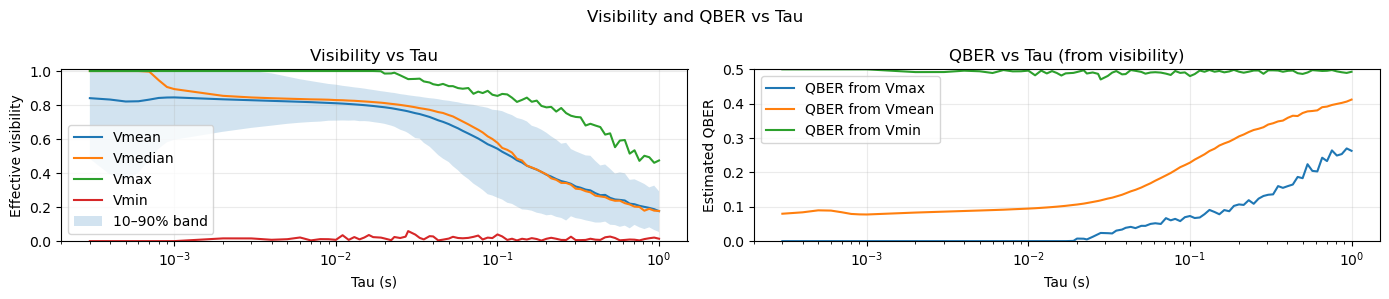

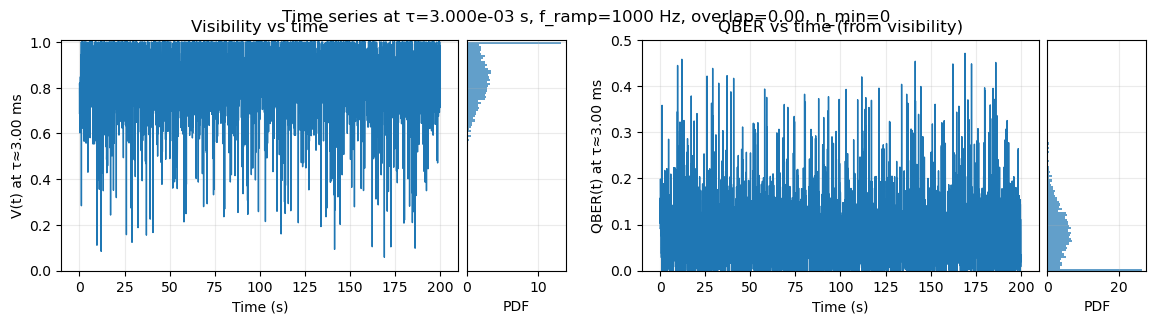

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 30, 'S_samples': 30, 'tau_eff_s': 0.003, 'step_eff_s': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.8441282440350173
V mean:   0.8280024557467223
V 10–90%: 0.6654549549363087 … 0.9999994444444444


In [7]:
DNF_1000_em2=Vis.AnalyseMeasurement_NewNumba(DNF,8,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

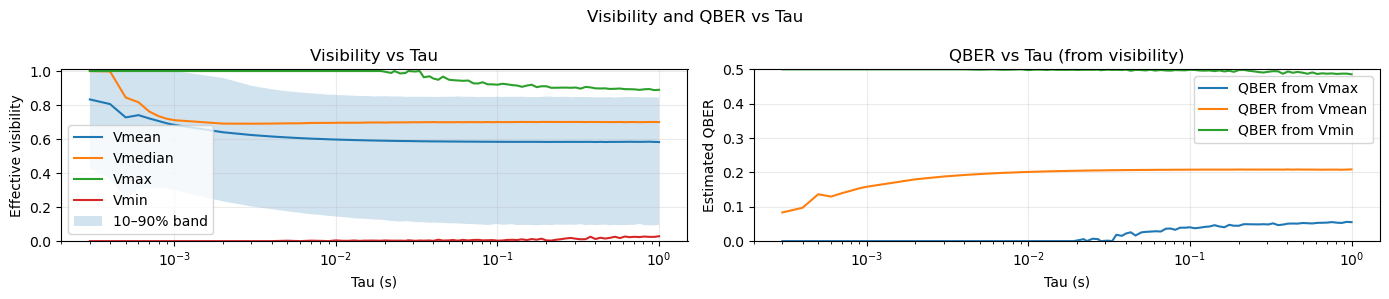

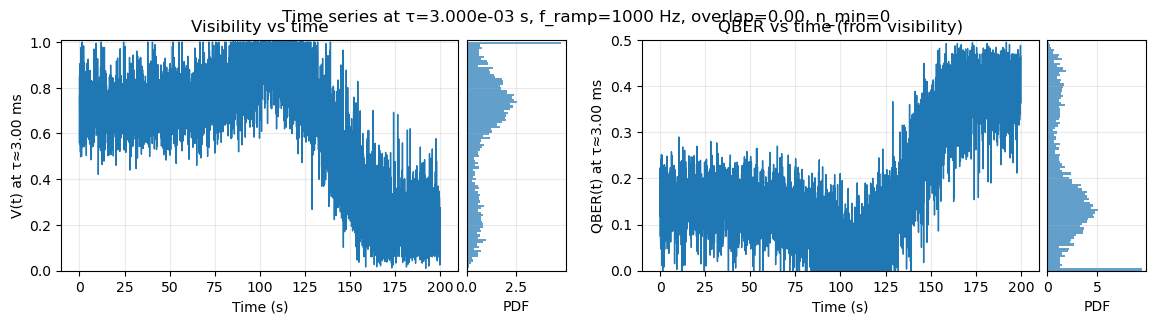

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 30, 'S_samples': 30, 'tau_eff_s': 0.003, 'step_eff_s': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.6897608466195114
V mean:   0.6234823222026779
V 10–90%: 0.20380465889487237 … 0.9123044987163043


In [9]:
DNF_1000_voa2=Vis.AnalyseMeasurement_NewNumba(DNF,0,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

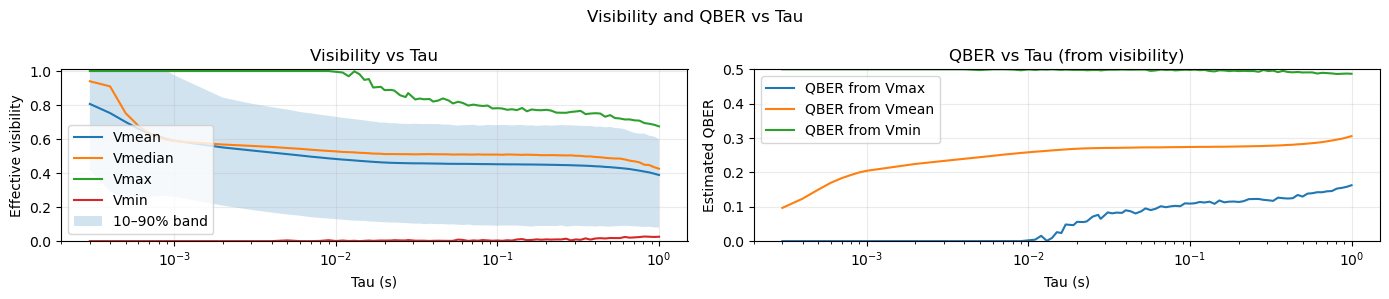

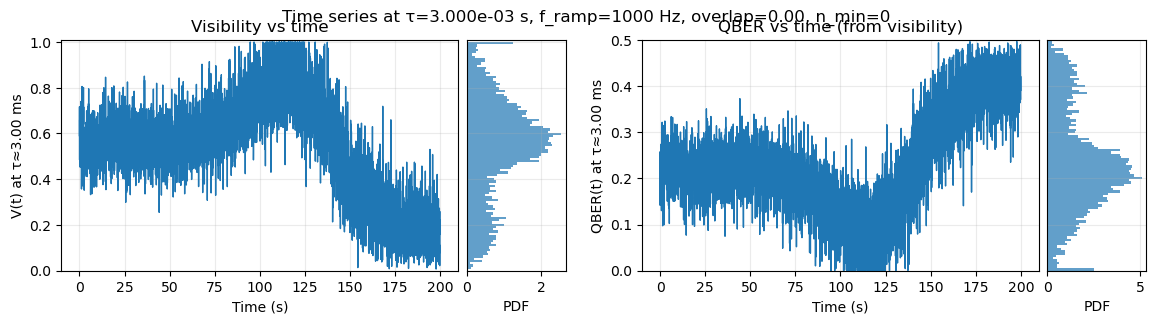

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 30, 'S_samples': 30, 'tau_eff_s': 0.003, 'step_eff_s': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.5596393382686193
V mean:   0.5328699180651544
V 10–90%: 0.18330265586166397 … 0.8079927243814766


In [35]:
DF_1000_voa2=Vis.AnalyseMeasurement_NewNumba(DF,1,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [36]:
np.save('DF_1000_voa_Numba.npy', np.array(DF_1000_voa2, dtype=object), allow_pickle=True)


In [29]:
DNF_1000_voa2

[[[array([1.500000e-03, 4.500000e-03, 7.500000e-03, ..., 1.999905e+02,
          1.999935e+02, 1.999965e+02]),
   array([0.85032321, 0.68571896, 0.74957374, ..., 0.27532131, 0.2677438 ,
          0.1138669 ]),
   {'dt': 0.0001,
    'K_samples': 30,
    'S_samples': 30,
    'tau_eff_s': 0.003,
    'step_eff_s': 0.003,
    'n_windows_total': 66666,
    'n_windows_used': 66666,
    'n_phase': 64,
    'iters_ab': 8,
    'lam_floor': 1e-06,
    'n_min_counts': 0.0,
    'clip_for_qber': False}],
  [array([1.500000e-03, 4.350000e-02, 8.550000e-02, ..., 1.998795e+02,
          1.999215e+02, 1.999635e+02]),
   array([0.85032321, 0.55845347, 0.76547674, ..., 0.2384071 , 0.27545176,
          0.0712761 ])],
  [array([1.500000e-03, 4.350000e-02, 8.550000e-02, ..., 1.998795e+02,
          1.999215e+02, 1.999635e+02]),
   array([0.07483839, 0.22077326, 0.11726163, ..., 0.38079645, 0.36227412,
          0.46436195])]],
 VisibilityTauResult(taus=array([3.00e-04, 4.00e-04, 5.00e-04, 6.00e-04, 7.00e-04,

In [12]:
np.save('DNF_1000_em_Numba.npy',DNF_1000_em2[1])

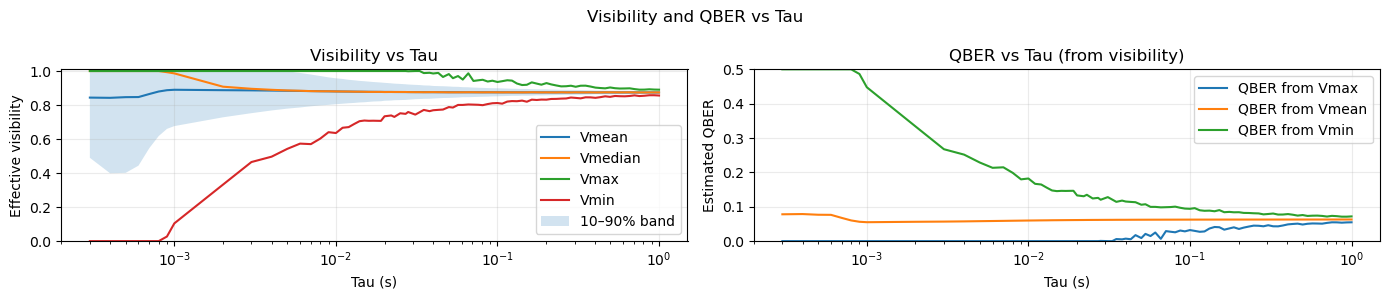

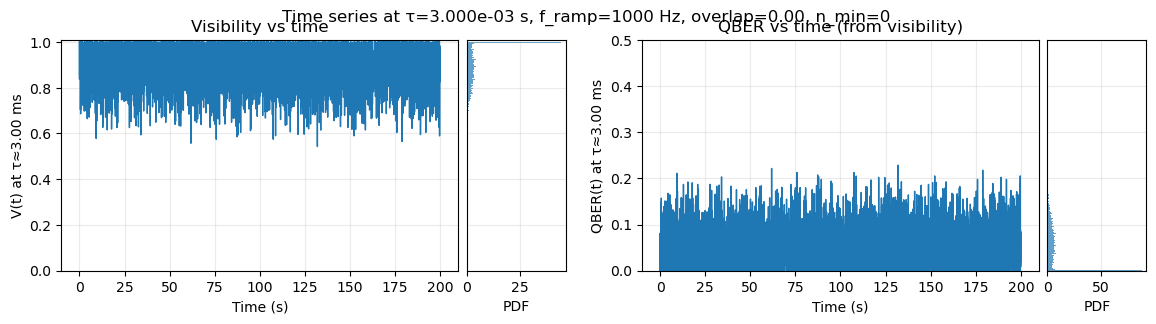

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 30, 'S_samples': 30, 'tau_eff_s': 0.003, 'step_eff_s': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.8948930443836687
V mean:   0.885844662741946
V 10–90%: 0.7518906607858125 … 0.9999995238095237


In [9]:
DNF_1000_nm2=Vis.AnalyseMeasurement_NewNumba(DNF,4,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [13]:
np.save('DNF_1000_nm_Numba.npy',DNF_1000_nm2[1])

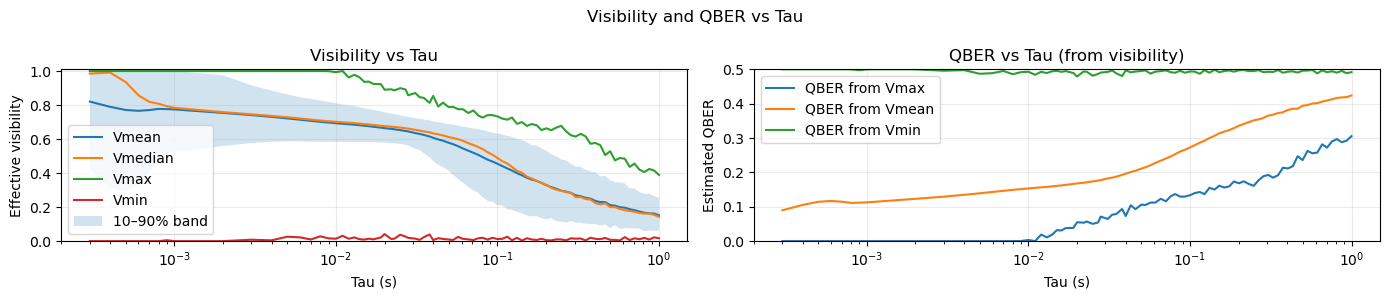

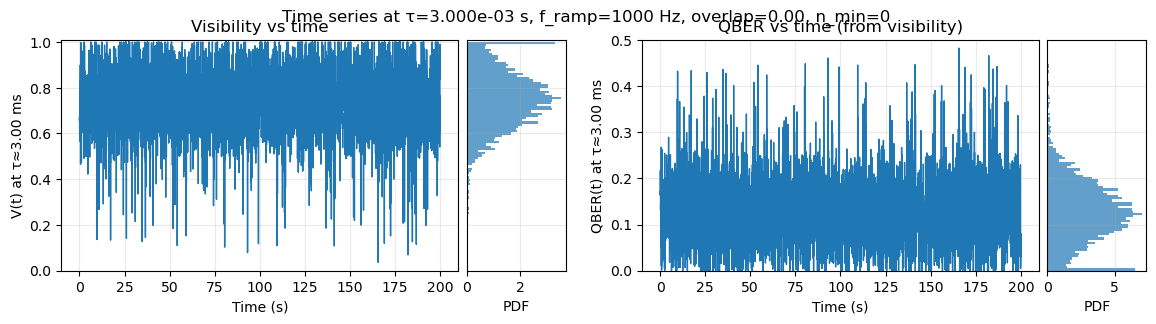

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 30, 'S_samples': 30, 'tau_eff_s': 0.003, 'step_eff_s': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.7453388563706733
V mean:   0.7406671569930008
V 10–90%: 0.5761736559251587 … 0.9154666821493853


In [15]:
DF_1000_em2=Vis.AnalyseMeasurement_NewNumba(DF,9,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [16]:
np.save('DF_1000_em_Numba.npy',DF_1000_em2[1])

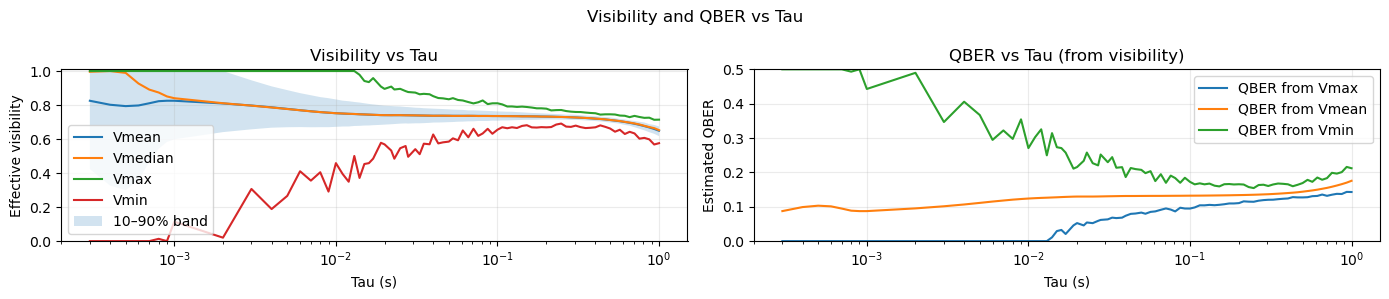

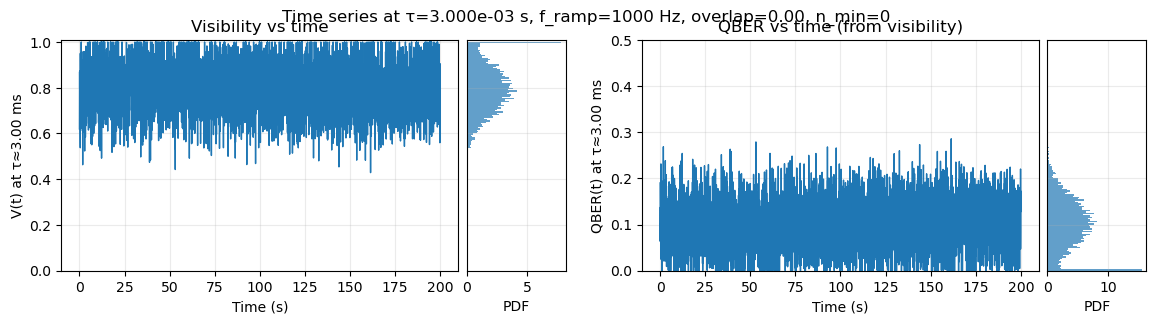

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 30, 'S_samples': 30, 'tau_eff_s': 0.003, 'step_eff_s': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.7959876680490052
V mean:   0.7966936855858223
V 10–90%: 0.6568931346937652 … 0.9448920602514777


In [17]:
DF_1000_nm2=Vis.AnalyseMeasurement_NewNumba(DF,5,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [18]:
np.save('DF_1000_nm_Numba.npy',DF_1000_nm2[1])

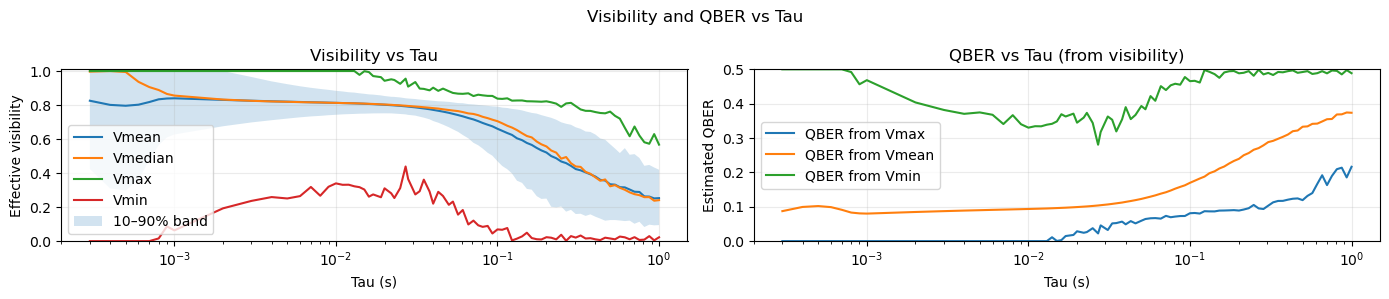

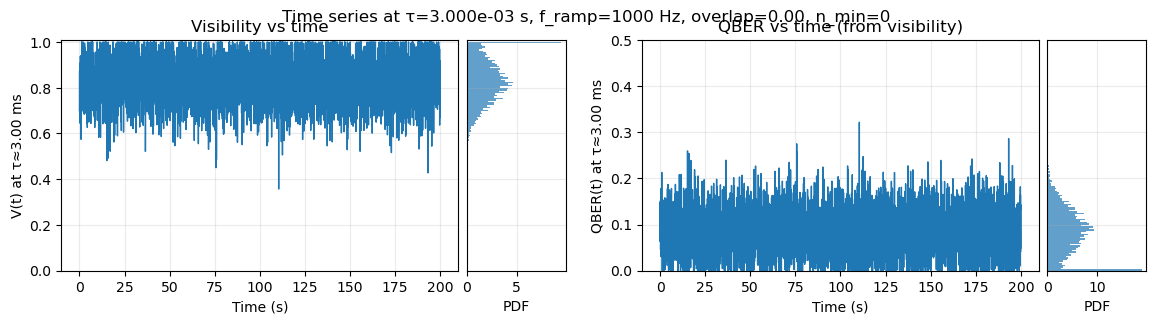

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 30, 'S_samples': 30, 'tau_eff_s': 0.003, 'step_eff_s': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.8244716329468436
V mean:   0.824953393221491
V 10–90%: 0.6974660871626461 … 0.9641395938959132


In [19]:
MNF_1000_em2=Vis.AnalyseMeasurement_NewNumba(MNF,8,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [20]:
np.save('MNF_1000_em_Numba.npy',MNF_1000_em2[1])

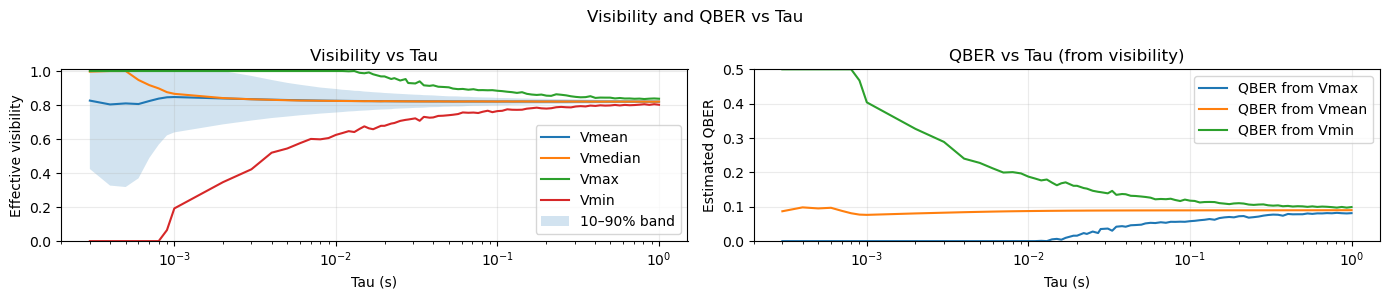

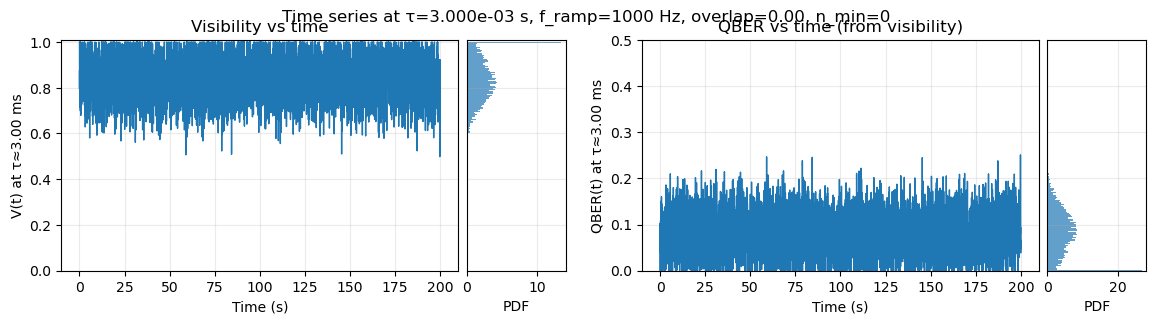

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 30, 'S_samples': 30, 'tau_eff_s': 0.003, 'step_eff_s': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.8334452852687411
V mean:   0.8340388989306914
V 10–90%: 0.7085969999097368 … 0.9704605484370313


In [21]:
MNF_1000_nm2=Vis.AnalyseMeasurement_NewNumba(MNF,4,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [22]:
np.save('MNF_1000_nm_Numba.npy',MNF_1000_nm2[1])

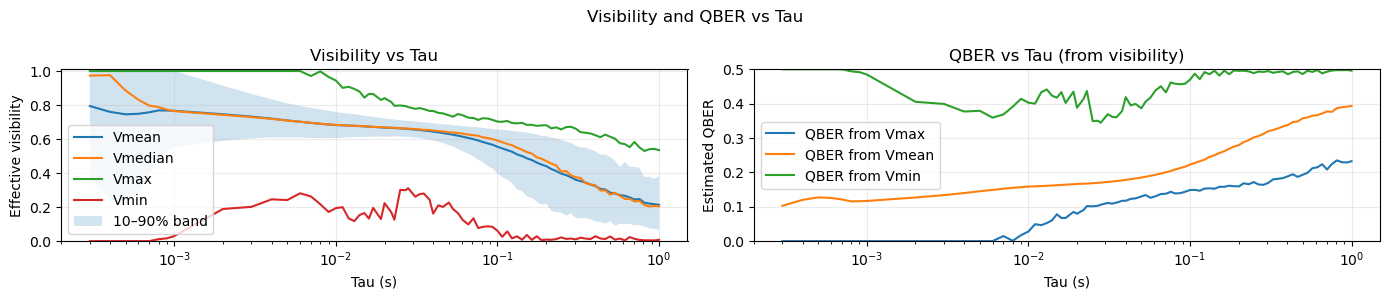

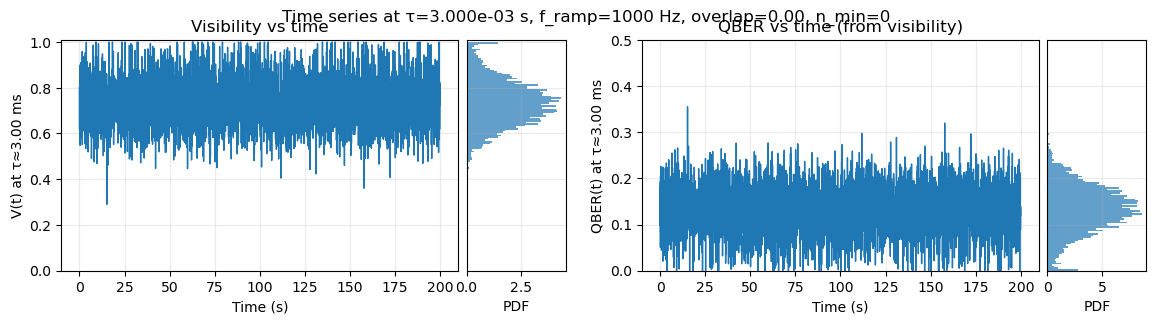

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 30, 'S_samples': 30, 'tau_eff_s': 0.003, 'step_eff_s': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.7291760935114602
V mean:   0.7317021068860328
V 10–90%: 0.6028852831814664 … 0.8646341656494793


In [26]:
MF_1000_em2=Vis.AnalyseMeasurement_NewNumba(MF,8,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [27]:
np.save('MF_1000_em_Numba.npy',MF_1000_em2[1])

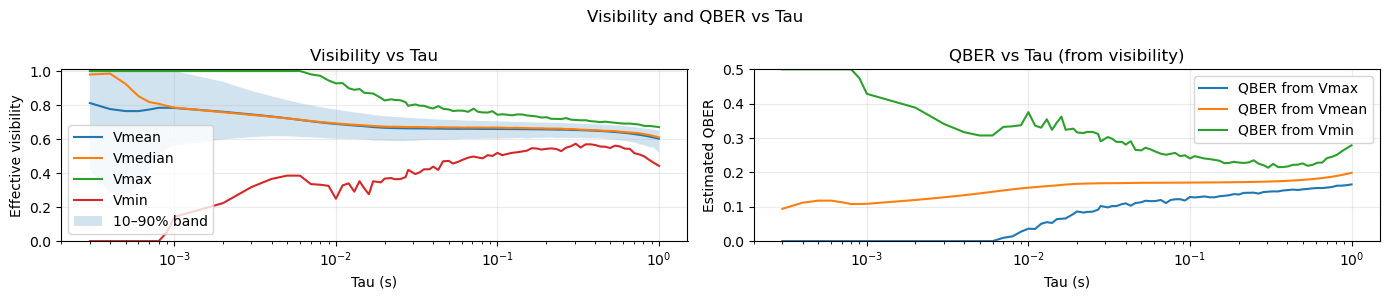

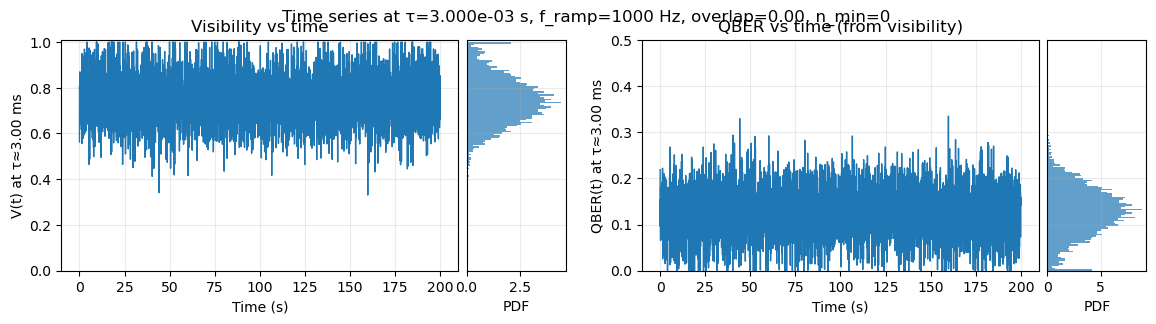

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 30, 'S_samples': 30, 'tau_eff_s': 0.003, 'step_eff_s': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.7418310835396594
V mean:   0.7444944654625156
V 10–90%: 0.6111538841458715 … 0.8822419429243848


In [28]:
MF_1000_nm2=Vis.AnalyseMeasurement_NewNumba(MF,4,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [29]:
np.save('MF_1000_nm_Numba.npy',MF_1000_nm2[1])

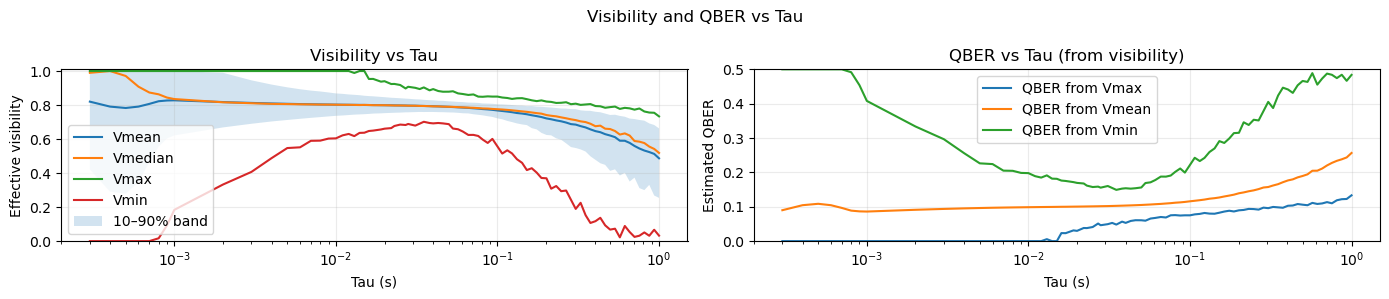

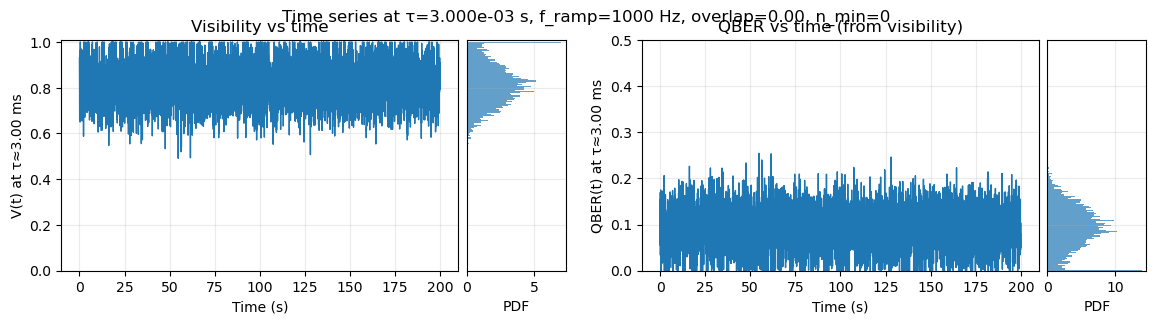

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 30, 'S_samples': 30, 'tau_eff_s': 0.003, 'step_eff_s': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.8102448624770008
V mean:   0.8120333980403873
V 10–90%: 0.6895723652921621 … 0.9444942702870467


In [30]:
NNF_1000_em2=Vis.AnalyseMeasurement_NewNumba(NNF,8,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [31]:
np.save('NNF_1000_em_Numba.npy',NNF_1000_em2[1])

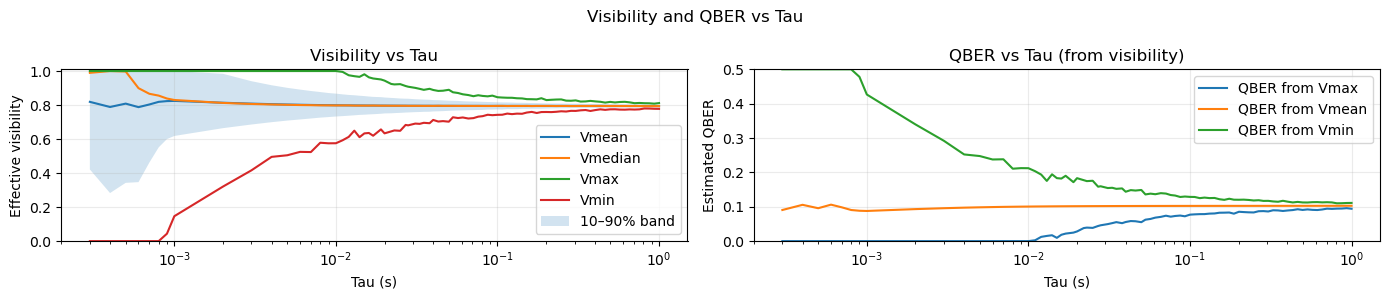

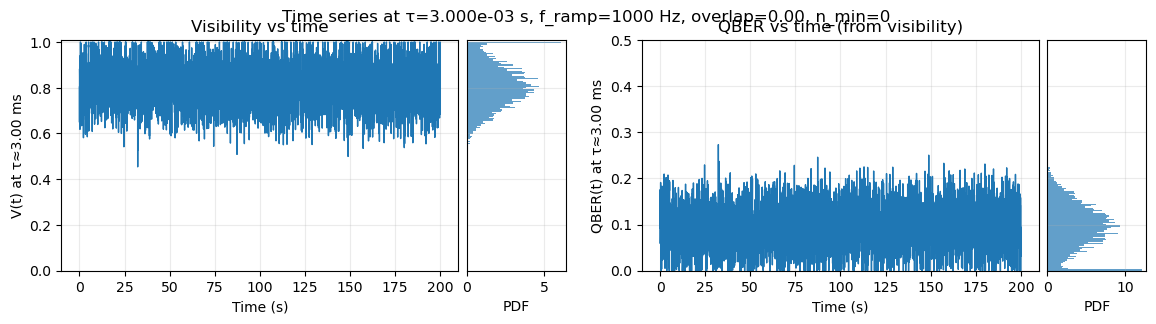

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 30, 'S_samples': 30, 'tau_eff_s': 0.003, 'step_eff_s': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.8060170750062148
V mean:   0.8078711404764234
V 10–90%: 0.685222928304416 … 0.9393997073660074


In [32]:
NNF_1000_nm2=Vis.AnalyseMeasurement_NewNumba(NNF,4,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [33]:
np.save('NNF_1000_nm_Numba.npy',NNF_1000_nm2[1])

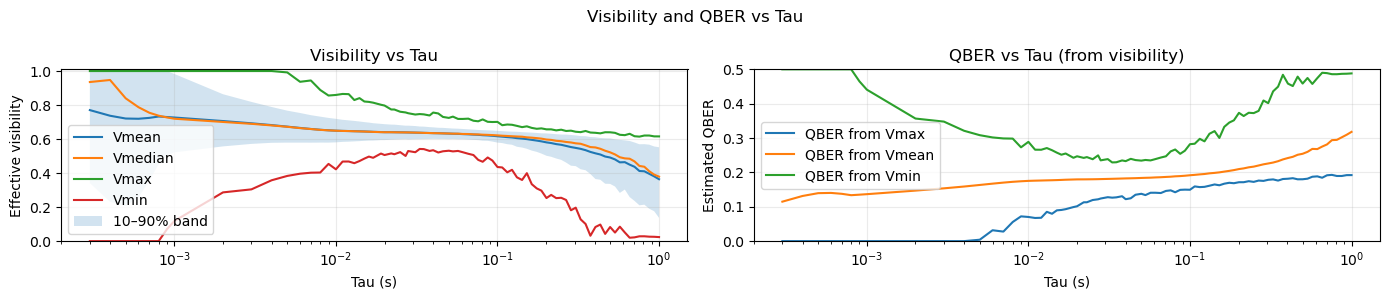

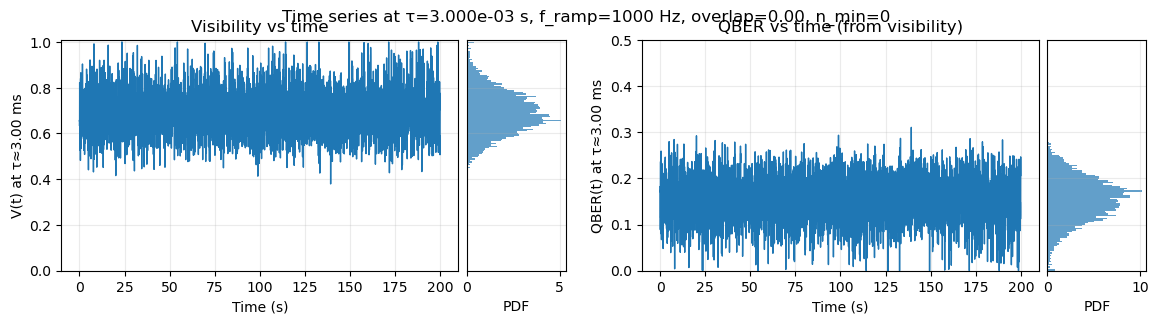

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 30, 'S_samples': 30, 'tau_eff_s': 0.003, 'step_eff_s': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.6891801061709492
V mean:   0.6923453064466424
V 10–90%: 0.5712793040738716 … 0.8180767763397198


In [34]:
NF_1000_em2=Vis.AnalyseMeasurement_NewNumba(NF,8,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [35]:
np.save('NF_1000_em_Numba.npy',NF_1000_em2[1])

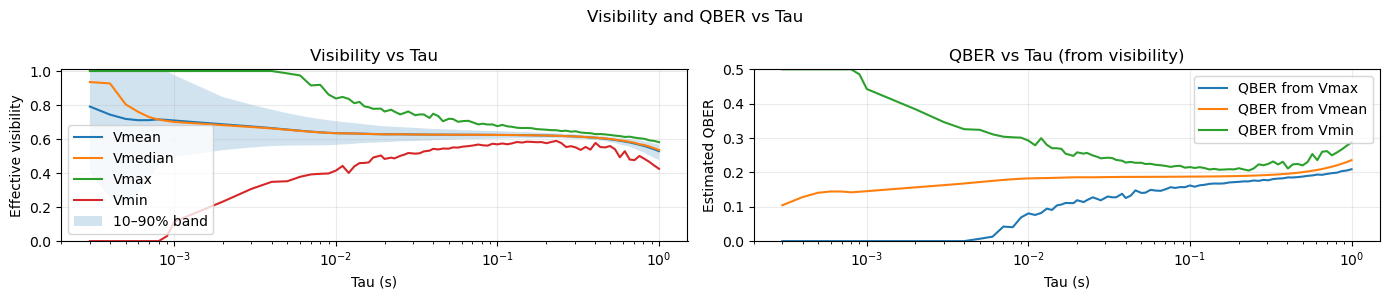

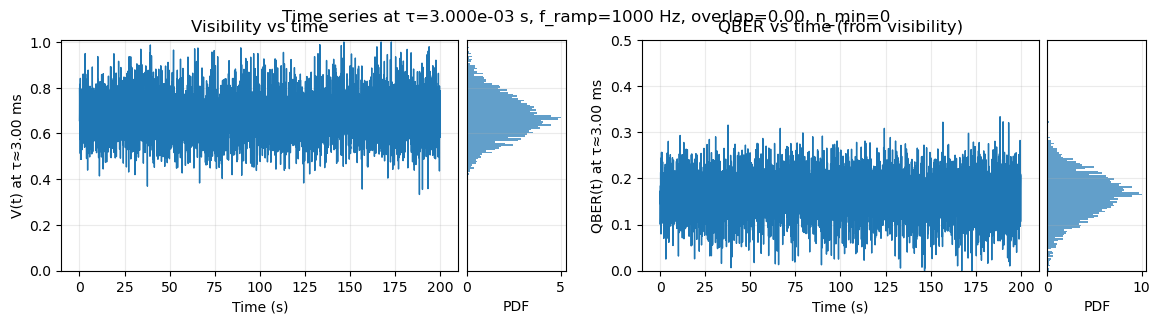

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 30, 'S_samples': 30, 'tau_eff_s': 0.003, 'step_eff_s': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.670619492295528
V mean:   0.6738822938478609
V 10–90%: 0.5502510522252392 … 0.801116401125246


In [36]:
NF_1000_nm2=Vis.AnalyseMeasurement_NewNumba(NF,4,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [37]:
np.save('NF_1000_nm_Numba.npy',NF_1000_nm2[1])

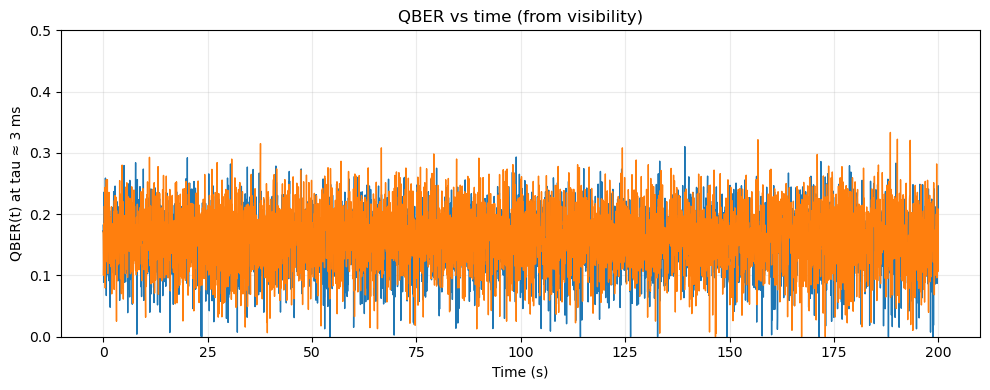

In [58]:
plt.figure(figsize=(10, 4))
plt.plot(NF_1000_em2[0][2][0], NF_1000_em2[0][2][1], linewidth=1)
plt.plot(NF_1000_nm2[0][2][0], NF_1000_nm2[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 3 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

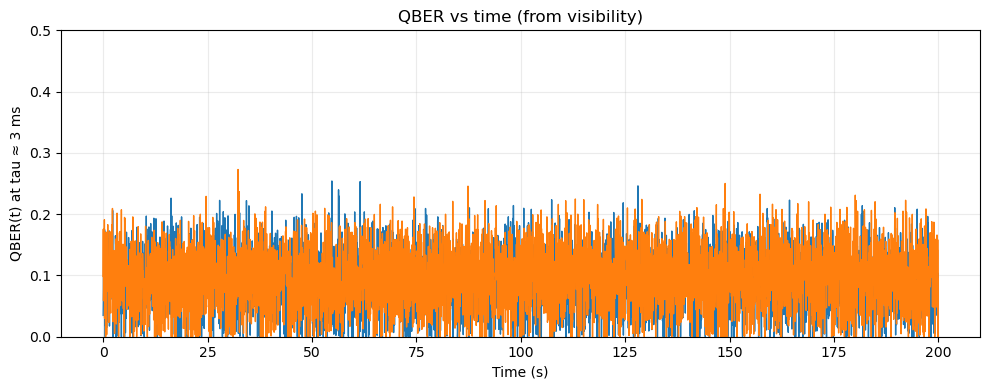

In [60]:
plt.figure(figsize=(10, 4))
plt.plot(NNF_1000_em2[0][2][0], NNF_1000_em2[0][2][1], linewidth=1)
plt.plot(NNF_1000_nm2[0][2][0], NNF_1000_nm2[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 3 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

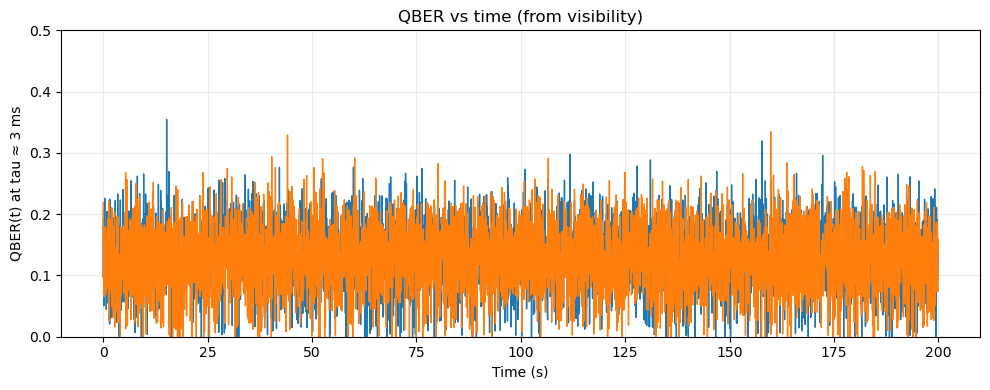

In [62]:
plt.figure(figsize=(10, 4))
plt.plot(MF_1000_em2[0][2][0], MF_1000_em2[0][2][1], linewidth=1)
plt.plot(MF_1000_nm2[0][2][0], MF_1000_nm2[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 3 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

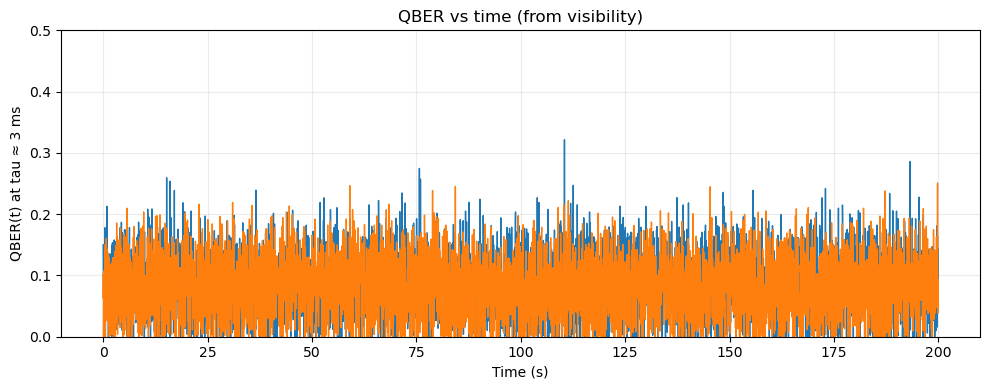

In [64]:
plt.figure(figsize=(10, 4))
plt.plot(MNF_1000_em2[0][2][0], MNF_1000_em2[0][2][1], linewidth=1)
plt.plot(MNF_1000_nm2[0][2][0], MNF_1000_nm2[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 3 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

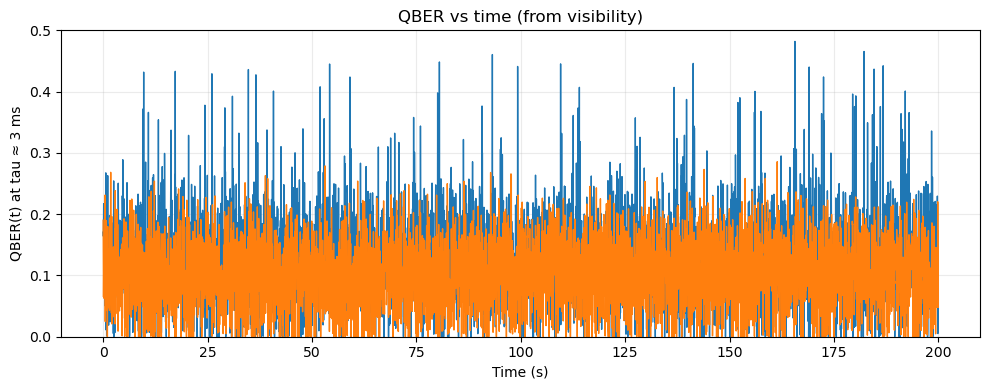

In [67]:
plt.figure(figsize=(10, 4))
plt.plot(DF_1000_em2[0][2][0], DF_1000_em2[0][2][1], linewidth=1)
plt.plot(DF_1000_nm2[0][2][0], DF_1000_nm2[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 3 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

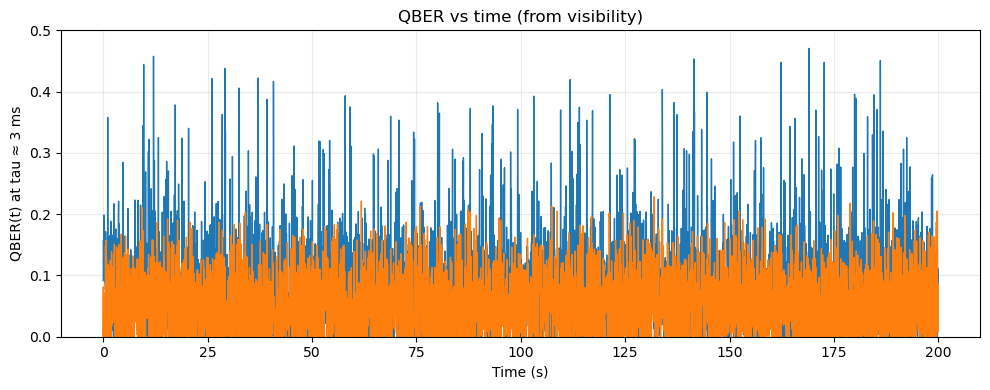

In [69]:
plt.figure(figsize=(10, 4))
plt.plot(DNF_1000_em2[0][2][0], DNF_1000_em2[0][2][1], linewidth=1)
plt.plot(DNF_1000_nm2[0][2][0], DNF_1000_nm2[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 3 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

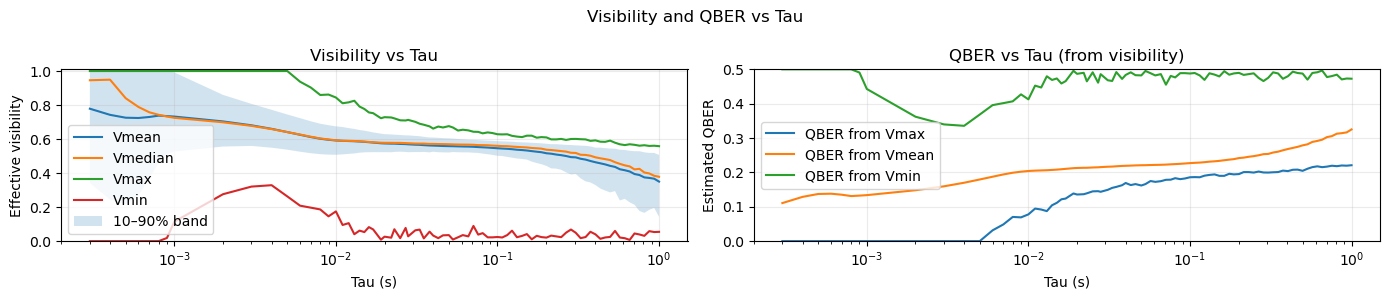

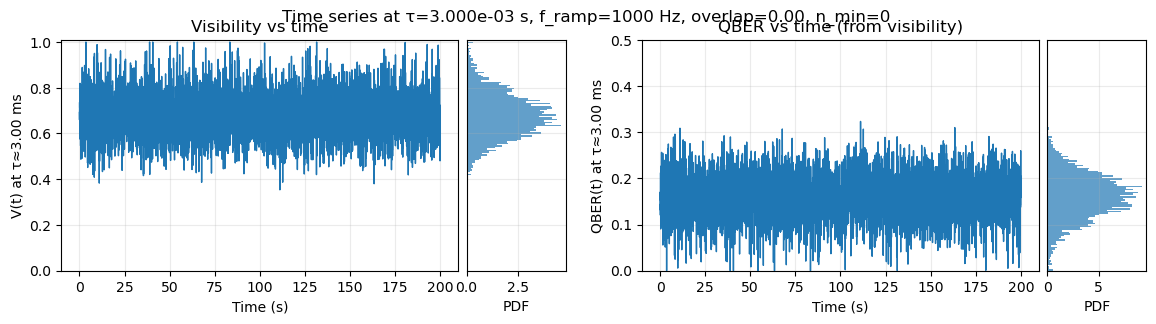

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 30, 'S_samples': 30, 'tau_eff_s': 0.003, 'step_eff_s': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.6772877155057981
V mean:   0.6806232672206172
V 10–90%: 0.559250458779202 … 0.8063649487332665


In [71]:
NL_1000_em2=Vis.AnalyseMeasurement_NewNumba(NL,8,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [72]:
np.save('NL_1000_em_Numba.npy',NL_1000_em2[1])

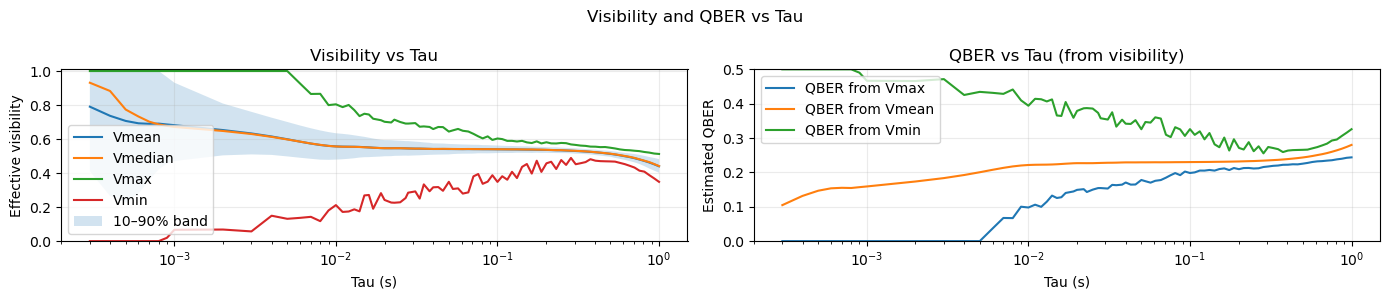

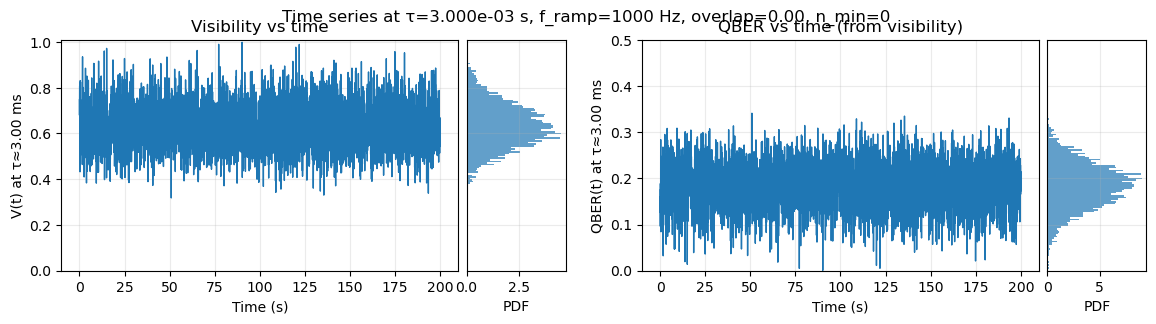

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 30, 'S_samples': 30, 'tau_eff_s': 0.003, 'step_eff_s': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.6295174943807456
V mean:   0.632770011608834
V 10–90%: 0.509651780662836 … 0.7596562019292514


In [73]:
NL_1000_nm2=Vis.AnalyseMeasurement_NewNumba(NL,4,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [74]:
np.save('NL_1000_nm_Numba.npy',NL_1000_nm2[1])

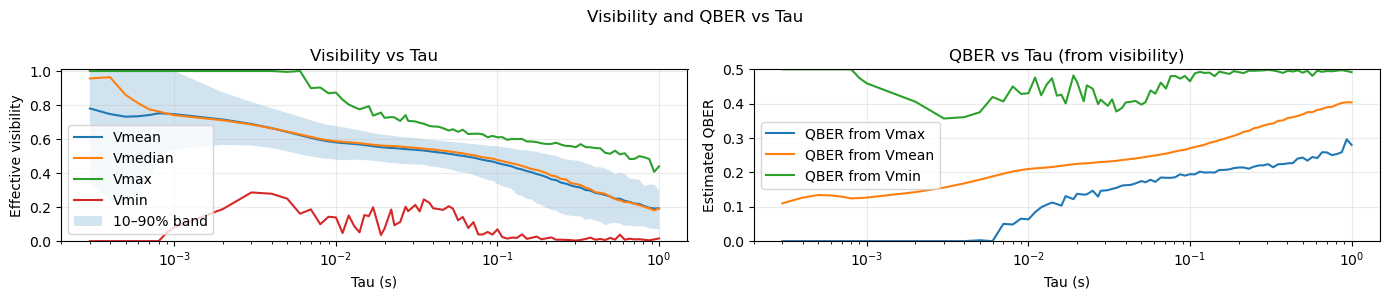

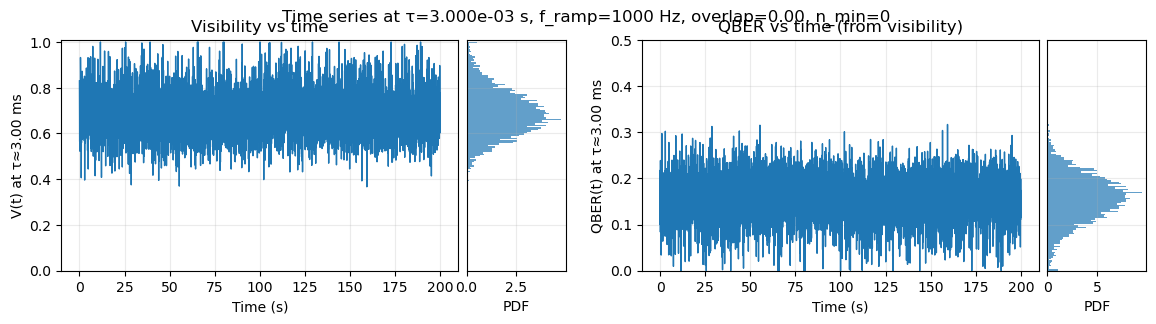

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 30, 'S_samples': 30, 'tau_eff_s': 0.003, 'step_eff_s': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.6855167587837523
V mean:   0.6880592836485762
V 10–90%: 0.5616237408604619 … 0.8172565460900161


In [75]:
NLF_1000_em2=Vis.AnalyseMeasurement_NewNumba(NLF,8,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [76]:
np.save('NLF_1000_em_Numba.npy',NLF_1000_em2[1])

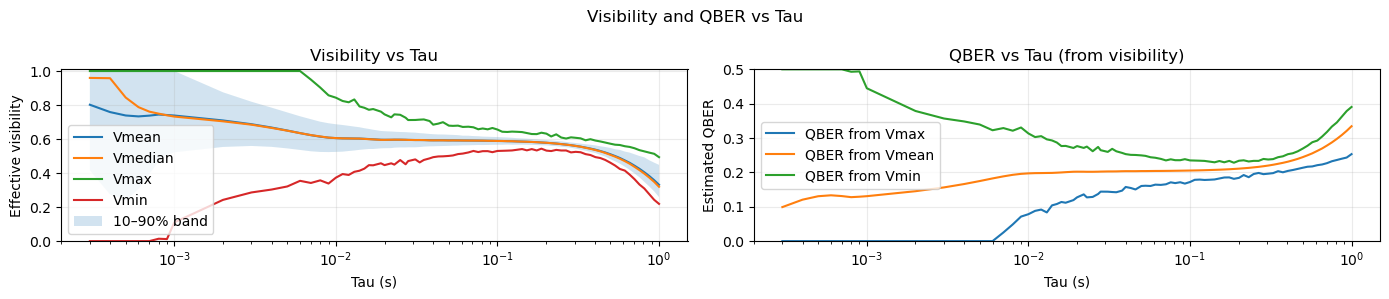

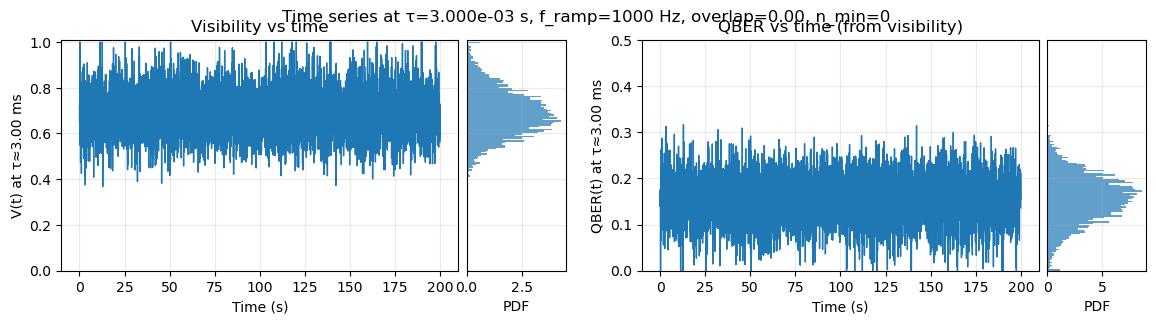

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 30, 'S_samples': 30, 'tau_eff_s': 0.003, 'step_eff_s': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.6842781523776968
V mean:   0.6870008789210289
V 10–90%: 0.5591980036220154 … 0.8192194102435041


In [77]:
NLF_1000_nm2=Vis.AnalyseMeasurement_NewNumba(NLF,4,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [78]:
np.save('NLF_1000_nm_Numba.npy',NLF_1000_nm2[1])

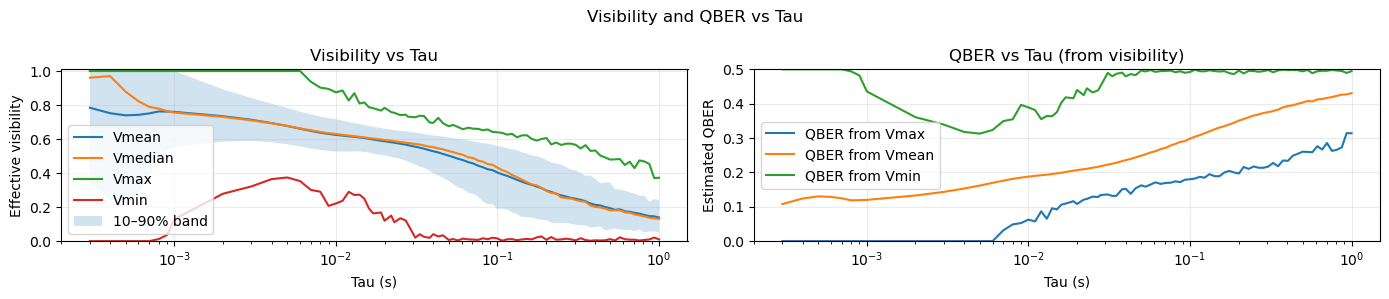

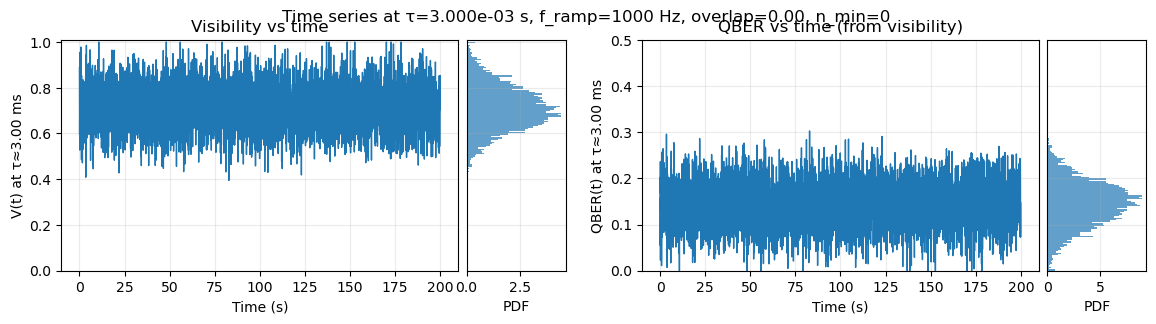

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 30, 'S_samples': 30, 'tau_eff_s': 0.003, 'step_eff_s': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.7098116686911435
V mean:   0.7129888013100852
V 10–90%: 0.5888857096648564 … 0.8408637554810336


In [79]:
NLVF_1000_em2=Vis.AnalyseMeasurement_NewNumba(NLVF,8,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [80]:
np.save('NLVF_1000_em_Numba.npy',NLVF_1000_em2[1])

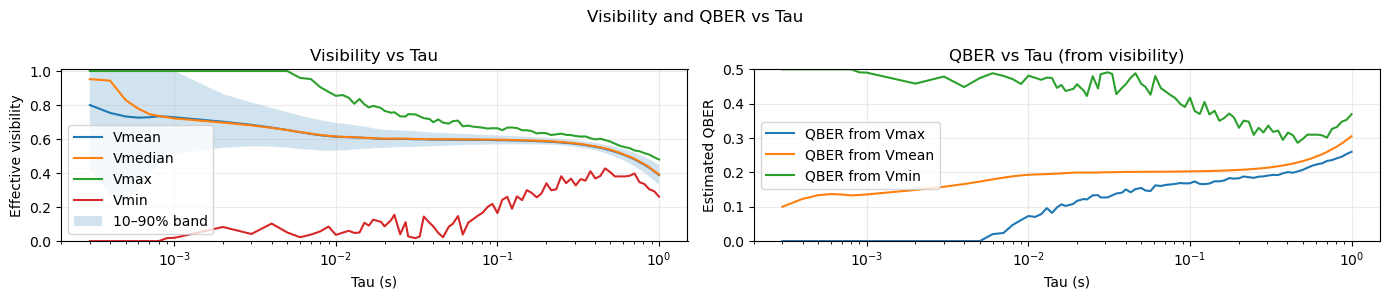

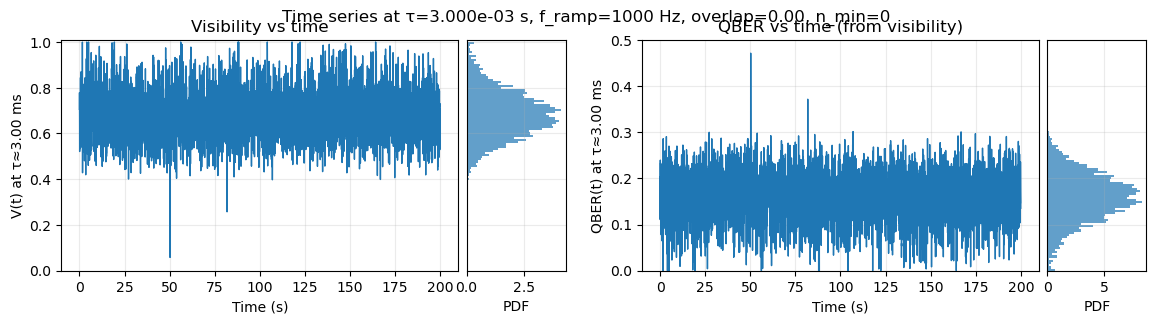

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 30, 'S_samples': 30, 'tau_eff_s': 0.003, 'step_eff_s': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.6802477616722242
V mean:   0.6833004247405413
V 10–90%: 0.5568880262811964 … 0.8148631411296701


In [81]:
NLVF_1000_nm2=Vis.AnalyseMeasurement_NewNumba(NLVF,4,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [82]:
np.save('NLVF_1000_nm_Numba.npy',NLVF_1000_nm2[1])

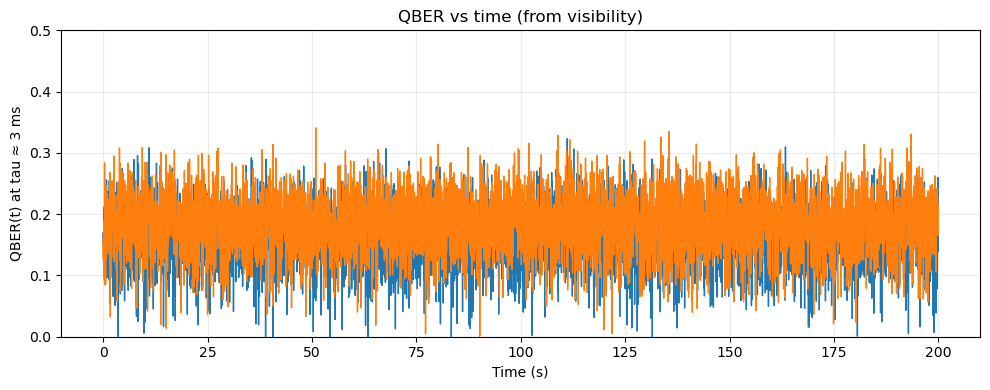

In [95]:
plt.figure(figsize=(10, 4))
plt.plot(NL_1000_em2[0][2][0], NL_1000_em2[0][2][1], linewidth=1)
plt.plot(NL_1000_nm2[0][2][0], NL_1000_nm2[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 3 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

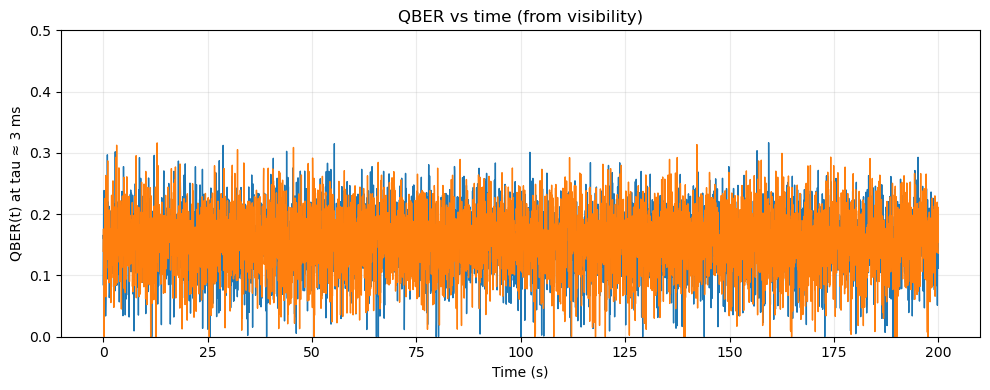

In [97]:
plt.figure(figsize=(10, 4))
plt.plot(NLF_1000_em2[0][2][0], NLF_1000_em2[0][2][1], linewidth=1)
plt.plot(NLF_1000_nm2[0][2][0], NLF_1000_nm2[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 3 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

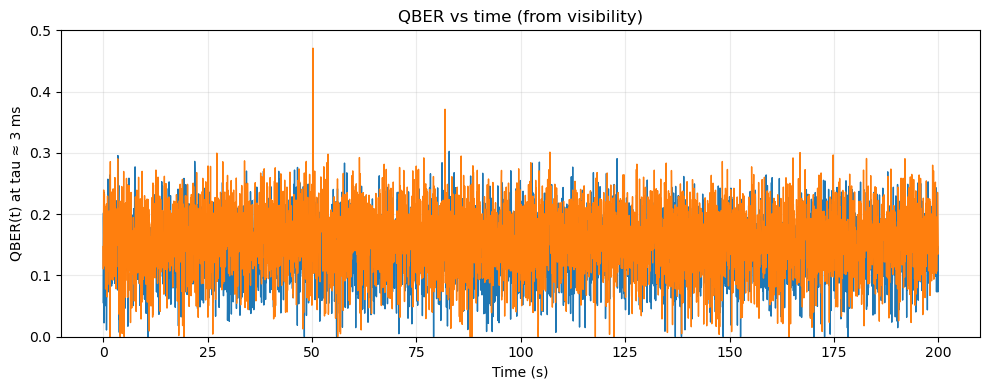

In [99]:
plt.figure(figsize=(10, 4))
plt.plot(NLVF_1000_em2[0][2][0], NLVF_1000_em2[0][2][1], linewidth=1)
plt.plot(NLVF_1000_nm2[0][2][0], NLVF_1000_nm2[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 3 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

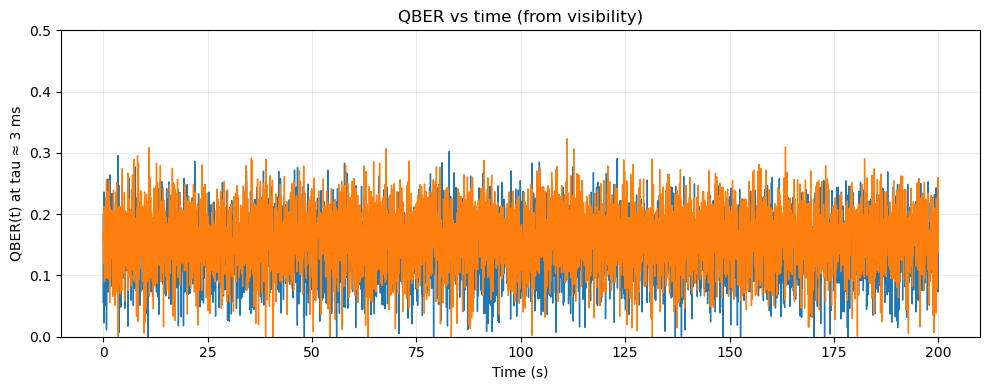

In [101]:
plt.figure(figsize=(10, 4))
plt.plot(NLVF_1000_em2[0][2][0], NLVF_1000_em2[0][2][1], linewidth=1)
plt.plot(NL_1000_em2[0][2][0], NL_1000_em2[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 3 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

In [106]:
np.save('NNF_1000_em_Numba.npy', np.array(NNF_1000_em2, dtype=object), allow_pickle=True)
np.save('NNF_1000_nm_Numba.npy', np.array(NNF_1000_nm2, dtype=object), allow_pickle=True)
np.save('NF_1000_em_Numba.npy', np.array(NF_1000_em2, dtype=object), allow_pickle=True)
np.save('NF_1000_nm_Numba.npy', np.array(NF_1000_nm2, dtype=object), allow_pickle=True)

In [108]:
np.save('MNF_1000_em_Numba.npy', np.array(MNF_1000_em2, dtype=object), allow_pickle=True)
np.save('MNF_1000_nm_Numba.npy', np.array(MNF_1000_nm2, dtype=object), allow_pickle=True)
np.save('MF_1000_em_Numba.npy', np.array(MF_1000_em2, dtype=object), allow_pickle=True)
np.save('MF_1000_nm_Numba.npy', np.array(MF_1000_nm2, dtype=object), allow_pickle=True)

In [110]:
np.save('DNF_1000_em_Numba.npy', np.array(DNF_1000_em2, dtype=object), allow_pickle=True)
np.save('DNF_1000_nm_Numba.npy', np.array(DNF_1000_nm2, dtype=object), allow_pickle=True)
np.save('DF_1000_em_Numba.npy', np.array(DF_1000_em2, dtype=object), allow_pickle=True)
np.save('DF_1000_nm_Numba.npy', np.array(DF_1000_nm2, dtype=object), allow_pickle=True)

In [112]:
np.save('NLVF_1000_em_Numba.npy', np.array(NLVF_1000_em2, dtype=object), allow_pickle=True)
np.save('NLVF_1000_nm_Numba.npy', np.array(NLVF_1000_nm2, dtype=object), allow_pickle=True)
np.save('NLF_1000_em_Numba.npy', np.array(NLF_1000_em2, dtype=object), allow_pickle=True)
np.save('NLF_1000_nm_Numba.npy', np.array(NLF_1000_nm2, dtype=object), allow_pickle=True)
np.save('NL_1000_em_Numba.npy', np.array(NL_1000_em2, dtype=object), allow_pickle=True)
np.save('NL_1000_nm_Numba.npy', np.array(NL_1000_nm2, dtype=object), allow_pickle=True)

In [31]:
np.save('DNF_1000_voa_Numba.npy', np.array(DNF_1000_voa2, dtype=object), allow_pickle=True)
